# Gevaert lab liver segmentation workflow

Important: Launch Jupyter notebook from XNAT project level to run this notebook.

This notebook rewrites the original Gevaert lab demo to use the updated
`workflow_adapters.py` API, following the same pattern as `example-workflow.ipynb`.
It demonstrates how to:

* analyze an XNAT project for structural scans and associated segmentations,
* build per-session job descriptors with `populate_job_fields()`,
* generate per-job shell scripts with `workflow_to_batch()`,
* optionally upload job bundles to XNAT and launch Container Service jobs.


## 1. Mandatory user-settable variables

Edit this cell to set the main notebook variables.


In [2]:
from pathlib import Path

#set to True to regenerate project directory structure saved in local json file.
rebuild_directory_structure=False

# XNAT project label
project='CRLM'

# Persistent workspace root path
root_dir=Path("/workspace/dnaxuser-wustl_mmilchenko_adapt")


## 2. General initializations

Run this cell to set up the notebook environment.


In [3]:
import os
import sys
import json
import datetime
import yaml
import importlib

# nibabel 5.4.x currently pulls NumPy 2.x, which can break this notebook stack.
! pip install nibabel==5.1.0
! pip install cmdline_provenance

# Library with XNAT Jupyter workflow Python and shell scripts.
pymipl_path = os.path.abspath('../')
sys.path.append(pymipl_path)
sys.path.append(os.path.abspath(pymipl_path + '/xnat_workflow'))

# dicom_sort is part of pymipl. It analyzes XNAT projects for structural scans
# and segmentations.
from dicom_sort import *

# Derived variable initializations
local_workdir_path = root_dir / project
xnat_project_path = f'/data/projects/{project}/experiments'
directory_structure_file = local_workdir_path / "project_dir_structure.json"
xnat_structure_file = local_workdir_path / "xnat_structure.json"
scanlist_file = local_workdir_path / "scans.csv"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 45.1 MB/s eta 0:00:0000:0100:01


## 3. Create a list of structural scans and associated segmentations

Run the next cell to analyze the project structure and build the scan list.


In [4]:
# analyze_dir finds all structural scans and segmentations (DICOM RTSTRUCT
# and DICOM Segmentation Object) in the project. The results are saved into a
# JSON file for quick rerun.
if rebuild_directory_structure:
    os.makedirs(os.path.dirname(directory_structure_file), exist_ok=True)
    d = analyze_dir(xnat_project_path, directory_structure_file)
else:
    with open(directory_structure_file, 'r') as file:
        d = json.load(file)

# This writes out a human-readable list of structural scans with segmentations
# into a CSV file.
subjects, scans = reindex_to_structurals_and_segs(
    d,
    xnat_structure_file,
    scanlist_file
)
print(f'Number of structural scans: {len(scans)}')
print('First scan: ', scans[0])


Number of structural scans: 197
First scan:  {'Subject': 'CRLM-CT-1087', 'Experiment': '12-10-1991-NA-CT_CHABDPEL_W_CONTRAST-52410', 'StructScan': '2', 'StructScanSerDesc': '', 'SegScan1': '100', 'SegScan1_SerDesc': 'Segmentation', 'SegScan1_SOPClass': 'Seg'}


In [ ]:
scans

## 4. Workflow initializations

This section configures the workflow using the updated adapter API.


In [5]:
import workflow_adapters as wa
import nibabel as nib

importlib.reload(wa)

# env_type controls where scripts are built and executed.
# jupyter: all processing runs in a single XNAT-Jupyter environment
# container: processing runs in dedicated containers, one per scan/session

#env_type='jupyter'
env_type='container'

# This is the label of the session resource where generated job scripts, logs,
# and output will be saved.
workflow_id='colon-mets-liver-segmentation-toolbox-20260430'

# Command ID of the dedicated container command.
xnat_command_id=29

# Command wrapper name of the dedicated container command.
# Update this if your XNAT command uses a different wrapper name.
xnat_command_wrapper_id='xnat-ai-workflow-gevaert-liver'

# User micromamba environment repository.
#user_env_repo='gevaert'
user_env_repo=None

# User source/resource directory.
#user_src_repo='nsclc-segmentation-codebase-20260317'
user_src_repo=None

if env_type == 'jupyter':
    global_vars = wa.init_global_vars(env_type, project,  workflow_id,
        g_user_env_repo=user_env_repo,
        g_user_src_repo=user_src_repo,
        g_local_workdir_path=local_workdir_path,
        g_pymipl_dir=root_dir / 'pymipl'
    )
elif env_type == 'container':
    global_vars = wa.init_global_vars(env_type, project, workflow_id)

global_vars


{'g_project': 'CRLM',
 'g_workflow_id': 'colon-mets-liver-segmentation-toolbox-20260430',
 'g_user_env_repo': 'NONE',
 'g_env_repo_dir': PosixPath('/opt/packages/user/env_repo'),
 'g_user_src_repo': 'NONE',
 'g_alg_repo_dir': PosixPath('/opt/packages/user/alg_repo'),
 'g_input_mount_path': PosixPath('/input'),
 'g_local_workdir_path': PosixPath('/workdir'),
 'g_pymipl_dir': PosixPath('/opt/packages/pymipl')}

## 5. Build per-session job descriptors and scripts

This cell uses the updated workflow API. It creates a job dictionary with
`populate_job_fields()`, appends workflow steps to `job['steps']`, writes
`job.yaml` and `job.sh`, and can optionally upload and launch jobs.


In [6]:
# List keys available from the scan table.
scans[0].keys()


dict_keys(['Subject', 'Experiment', 'StructScan', 'StructScanSerDesc', 'SegScan1', 'SegScan1_SerDesc', 'SegScan1_SOPClass'])

In [7]:
import workflow_adapters as wa
import importlib
importlib.reload(wa)

##################################################################
# Variables that control execution logic.

# Start and end positions in the CSV-derived scan list.
start_pos=1
end_pos=1

# Whether to upload the generated job script bundle to the session resource.
UpdateSessionResource=0

# Whether to run the container immediately after upload.
RunContainer=0

#################################################################
# Other initializations
wa.set_logger()
dt = datetime.datetime.now().strftime("%Y%m%d_%H%M")
batch_file = local_workdir_path / f"batch_{dt}.sh"
n = 0
xnat_interface = None
num_sessions = len(scans)

# Main loop over structural scans. This builds the per-scan script and,
# optionally, uploads and launches it.
for scan in scans:
    n = n + 1
    if n < start_pos or n > end_pos:
        continue

    ##########################################################################
    # Initialize job context with the updated API.
    job = wa.populate_job_fields(env_type, global_vars, workflow_id, scan)

    # Workflow-specific job variables.
    job['job_struct_path'] = job['job_scan_context'] / scan['StructScan'] / 'DICOM'

    ##########################################################################
    # Add workflow steps.

    step = {'step_title': "1. Run liver segmentation on structural scan"}
    step['step_command'] = (
        "micromamba run -p {g_env_repo_dir} liver-segmentation "
        "--input {job_struct_path} "
        "--output-dir {job_workdir} "
        "--output-formats nifti"
    )
    job['steps'] += [step]

    step = {'step_title': "2. Convert structural scan to NIFTI"}
    step['step_command'] = (
        "micromamba run -n base python {g_pymipl_dir}/test_rt-utils.py "
        "{job_struct_path} {job_workdir}/ct"
    )
    job['steps'] += [step]

    step = {'step_title': "3. Generate QC image"}
    step['step_command'] = (
        "micromamba run -n base python {g_pymipl_dir}/slice_qc.py "
        "-o {job_workdir}/qc.png "
        "--mask {job_workdir}/liver_mask.nii.gz "
        "{job_workdir}/ct_struct.nii"
    )
    job['steps'] += [step]

    step = {'step_title': "4. Clean up intermediate files"}
    step['step_command'] = (
        "rm {job_workdir}/ct_struct.nii"
    )
    job['steps'] += [step]

    step = {'step_title': "5. Upload results to XNAT"}
    step['step_command'] = (
        "micromamba run -n base python "
        "{g_pymipl_dir}/xnat_workflow/sync-resource-with-xnat.py "
        "--level experiment "
        "--project {g_project} "
        "--subject {job_subject} "
        "--experiment {job_exp_label} "
        "--local_resource {job_workdir} "
        "--remote_resource {g_workflow_id} "
        "--create_hierarchy 1"
    )
    job['steps'] += [step]

    ##########################################################################
    # Write configuration and the final script.
    local_job_dir = local_workdir_path / 'jobs' / job['job_id']
    job_file_yaml = local_job_dir / 'job.yaml'
    job_file_sh = local_job_dir / 'job.sh'
    local_job_dir.mkdir(parents=True, exist_ok=True)

    with open(job_file_yaml, "w") as f:
        yaml.safe_dump(wa.paths_to_str(job), f, sort_keys=False)

    if env_type == 'jupyter':
        if not Path(batch_file).exists():
            with open(batch_file, 'w') as f:
                f.write('#!/bin/bash\n')
                f.write('export PATH="$PATH":/workspace/mmilchenko/bin\n')
                f.write('eval "$(micromamba shell hook --shell bash)"\n')

        wa.workflow_to_batch(job, global_vars, batch_file)
        print(f'Written {batch_file}')

    else:
        print(f'Written {job_file_sh}')
        Path(job_file_sh).write_text('')
        wa.workflow_to_batch(job, global_vars, job_file_sh)
        Path(job_file_sh).chmod(0o755)

        if UpdateSessionResource or RunContainer:
            if xnat_interface is None:
                xnat_interface = wa.get_xnat_interface(project)

        if UpdateSessionResource:
            print('Sending job bundle to XNAT resource')
            res1 = wa.resource_to_xnat(
                local_job_dir,
                workflow_id,
                project,
                job['job_subject'],
                job['job_exp_label'],
                xnat_interface
            )
            if res1 != 0:
                raise ConnectionError(
                    "Uploading job configuration to XNAT failed"
                )

        if RunContainer:
            print('Submitting job to Container Service')
            exp_id = (
                xnat_interface
                .select.project(project)
                .subject(job['job_subject'])
                .experiment(job['job_exp_label'])
                .id()
            )

            res2 = wa.launch_cs_command(
                xnat_interface,
                project,
                job['job_subject'],
                job['job_exp_label'],
                exp_id,
                workflow_id,
                xnat_command_id,
                xnat_command_wrapper_id,
                verbose=True
            )
            if not res2:
                raise ConnectionError("Launching container job failed")

        if n % 10 == 0:
            print(f'Done {n} out of {num_sessions} ({n*100/num_sessions:.1f}%)')

Written /workspace/mmilchenko/CRLM/jobs/colon-mets-liver-segmentation-toolbox-20260430_CRLM-CT-1087_12-10-1991-NA-CT_CHABDPEL_W_CONTRAST-52410/job.sh


## 6. Check for missing outputs

Run the next cell after jobs finish to identify sessions without expected output.


In [ ]:
n = 0
n_failed = 0
sessions_failed = []

for scan in scans:
    n = n + 1
    if n < start_pos or n > end_pos:
        continue

    job = wa.populate_job_fields(env_type, global_vars, workflow_id, scan)
    expected_mask = job['job_workdir'] / 'lesion_mask.nii.gz'
    expected_qc = job['job_workdir'] / 'qc.png'

    if not expected_mask.exists() or not expected_qc.exists():
        n_failed += 1
        sessions_failed.append({
            'Subject': job['job_subject'],
            'Experiment': job['job_exp_label'],
            'mask_exists': expected_mask.exists(),
            'qc_exists': expected_qc.exists()
        })

print(f'Failed sessions: {n_failed}')
sessions_failed[:10]


7. Compute Dice coefficient between the manual and automatic segmentations. 

In [ ]:
import json
import numpy as np
import nibabel as nib
from pathlib import Path
import importlib
import test_highdicom
from scipy.ndimage import binary_erosion, generate_binary_structure
from scipy.spatial import cKDTree
import csv

importlib.reload(test_highdicom)
dicomseg2nii = test_highdicom.dicomseg2nii

def dice_coefficient(mask_a, mask_b, label_b=None):
    mask_a = mask_a.astype(bool)
    mask_b = mask_b.astype(bool) if label_b is None else mask_b == label_b
    denom = mask_a.sum() + mask_b.sum()

    if denom == 0:
        return 1.0

    return float(2 * np.logical_and(mask_a, mask_b).sum() / denom)

def average_surface_distance_mm(mask_a, mask_b, image_a, image_b):
    mask_a = np.asarray(mask_a, dtype=bool)
    mask_b = np.asarray(mask_b, dtype=bool)

    if not mask_a.any() and not mask_b.any():
        return 0.0
    if not mask_a.any() or not mask_b.any():
        return float('inf')

    def surface_points_mm(mask, image):
        surface = mask & ~binary_erosion(
            mask,
            structure=generate_binary_structure(3, 1),
            border_value=0,
        )
        points = nib.affines.apply_affine(
            image.affine, np.argwhere(surface)
        )
        unit = image.header.get_xyzt_units()[0]
        # Undeclared spatial units are assumed to be millimeters.
        scale = {
            'mm': 1.0,
            'meter': 1000.0,
            'micron': 0.001,
            'unknown': 1.0,
        }[unit]
        return points * scale

    points_a = surface_points_mm(mask_a, image_a)
    points_b = surface_points_mm(mask_b, image_b)

    distances_a = cKDTree(points_b).query(points_a)[0]
    distances_b = cKDTree(points_a).query(points_b)[0]

    return float(
        (distances_a.sum() + distances_b.sum())
        / (distances_a.size + distances_b.size)
    )
dice_scores = []
surface_distances = []
tumor_segments = []
processed_experiments = []


model_resource1 = 'ABDOMINAL_CT_SEGMENTATION'
model_resource2 = 'Colon-Mets-Liver-Segmentation-Toolbox-20260430'
start_pos,end_pos=1,999

for i, scan in enumerate(scans):
    try:
        n = i + 1
        if n < start_pos or n > end_pos:
            continue
        processed_experiments += [scan['Experiment']]
        exp_dir = Path(xnat_project_path) / scan['Experiment']
        manual_seg_dir = exp_dir / 'SCANS' / scan['SegScan1'] / 'secondary'
        raw_struct_file = exp_dir / 'RESOURCES' / model_resource2 / 'ct_struct.nii.gz'
        nnunet_seg_mask = exp_dir / 'RESOURCES' / model_resource1 / ('scan'+scan['StructScan']) / 'nnunet_output' / 'ct_struct.nii.gz'
        work_dir = dice_root / scan['Experiment']
        work_dir.mkdir(parents=True, exist_ok=True)
    
        dicomseg_files = sorted(manual_seg_dir.glob('*.dcm'))
        if len(dicomseg_files) != 1:
            print(f'Expected one DICOM SEG file in {rtstruct_dir}, found {len(dicomseg_files)}, skipping')
            continue
            
        #print(dicomseg_files)
        
        if not nnunet_seg_mask.exists():
            print(f'WARNING: model mask not found: {model_mask_file}, skipping')
            continue
        if not raw_struct_file.exists():
            print(f'WARNING: raw structural NIFTI not found: {raw_struct_file}, skipping')
            continue
        
        
        manual_mask_file = work_dir / 'All_Tumors.nii.gz'
        #print(f'manual mask: {manual_mask_file}')
        #print(f'raw struct file: {raw_struct_file}')
        #print(f'dicomseg_file: {dicomseg_files[0]}')
        #print(f'output dir: {work_dir}')
        
        component_mask_files = [Path(p) for p in dicomseg2nii(
            str(dicomseg_files[0]),
            str(raw_struct_file),
            str(work_dir)
        )]
        liver_files=[p for p in component_mask_files if 'Liver' in p.name]
        component_mask_files = [p for p in component_mask_files if 'Tumor' in p.name]
        this_tumor_segments=len(component_mask_files)
        if this_tumor_segments < 1:        
            raise ValueError(f'No Tumor segment masks written for {dicomseg_files[0]}')
        tumor_segments+=[this_tumor_segments]
        print (f'Tumor segments:{len(component_mask_files)}')
        #print (f'manual masks: {component_mask_files}')
    
        manual_mask_data = np.zeros(nib.load(component_mask_files[0]).shape, dtype=bool)
        for component_mask_file in component_mask_files:
            manual_mask_data |= nib.load(component_mask_file).get_fdata() > 0
        
    
        raw_struct_img = nib.load(raw_struct_file)
        #print (f'liver mask file: {liver_files[0]}')
        #print (f'manual tumor mask file: {manual_mask_file}')
        #print (f'nnunet mask file: {nnunet_seg_mask}')
        nib.save(
            nib.Nifti1Image(manual_mask_data.astype(np.uint8), raw_struct_img.affine, raw_struct_img.header),
            manual_mask_file,
        )
    
        manual_mask = nib.load(manual_mask_file).get_fdata() > 0
        model_mask = nib.load(nnunet_seg_mask).get_fdata()  
        
        if manual_mask.shape != model_mask.shape:
            raise ValueError(
                f'Mask shape mismatch for {scan["Experiment"]}: '
                f'manual {manual_mask.shape}, model {model_mask.shape}'
            )
        dice_score = dice_coefficient(manual_mask, model_mask, label_b=9)
        print(f'dice score: {dice_score}')
        scans[i]['dice_score'] = dice_score
        dice_scores+=[dice_score]
    
        surface_distance_mm = average_surface_distance_mm(
            manual_mask,
            model_mask == 9,
            nib.load(manual_mask_file),
            nib.load(nnunet_seg_mask),
        )
        surface_distances+=[surface_distance_mm]
        print(f'average surface distance (mm): {surface_distance_mm}')
        scans[i]['average-surface-distance-mm'] = surface_distance_mm
        
    except Exception as e:
        print(f"skipping experiment {scan['Experiment']} due to an exception")
        
csv_file = dice_root / 'segmentation_metrics.csv'
with csv_file.open('w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['experiment', 'dice-score', 'average-surface-distance-mm', 'tumor-segments'])
    writer.writerows(zip(processed_experiments, dice_scores, surface_distances, tumor_segments, strict=True))



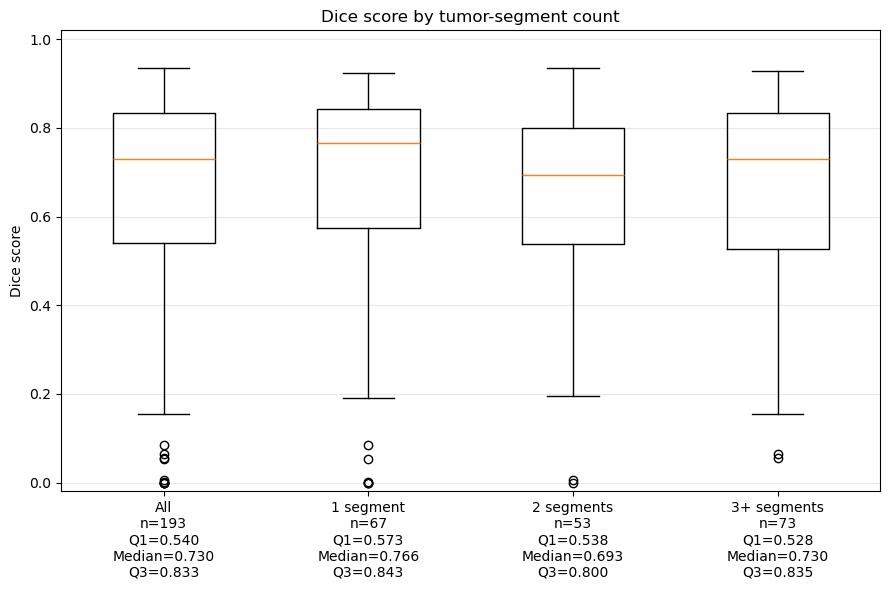

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(csv_file)
dice = pd.to_numeric(df["dice-score"], errors="coerce")
count = pd.to_numeric(df["tumor-segments"], errors="coerce")
groups = {"All": dice.dropna(), "1 segment": dice[count == 1].dropna(), "2 segments": dice[count == 2].dropna(), "3+ segments": dice[count >= 3].dropna()}

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(list(groups.values()), showfliers=True, whis=1.5, widths=0.5)
labels = []
for name, values in groups.items():
    q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
    labels.append(f"{name}\nn={len(values)}\nQ1={q1:.3f}\nMedian={median:.3f}\nQ3={q3:.3f}")
ax.set_xticks(range(1, 5))
ax.set_xticklabels(labels)
ax.set(ylabel="Dice score", ylim=(-0.02, 1.02), title="Dice score by tumor-segment count")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

In [13]:
scans[0]

{'Subject': 'CRLM-CT-1087',
 'Experiment': '12-10-1991-NA-CT_CHABDPEL_W_CONTRAST-52410',
 'StructScan': '2',
 'StructScanSerDesc': '',
 'SegScan1': '100',
 'SegScan1_SerDesc': 'Segmentation',
 'SegScan1_SOPClass': 'Seg',
 'dice_score': 0.5792227204783259}

In [ ]:
#Dice coefficient for TotalSeg.

import json
import numpy as np
import nibabel as nib
from pathlib import Path
import importlib
import test_highdicom
from scipy.ndimage import binary_erosion, generate_binary_structure
from scipy.spatial import cKDTree
import csv

importlib.reload(test_highdicom)
dicomseg2nii = test_highdicom.dicomseg2nii

def dice_coefficient(mask_a, mask_b, label_b=None):
    mask_a = mask_a.astype(bool)
    mask_b = mask_b.astype(bool) if label_b is None else mask_b == label_b
    denom = mask_a.sum() + mask_b.sum()

    if denom == 0:
        return 1.0

    return float(2 * np.logical_and(mask_a, mask_b).sum() / denom)

def average_surface_distance_mm(mask_a, mask_b, image_a, image_b):
    mask_a = np.asarray(mask_a, dtype=bool)
    mask_b = np.asarray(mask_b, dtype=bool)

    if not mask_a.any() and not mask_b.any():
        return 0.0
    if not mask_a.any() or not mask_b.any():
        return float('inf')

    def surface_points_mm(mask, image):
        surface = mask & ~binary_erosion(
            mask,
            structure=generate_binary_structure(3, 1),
            border_value=0,
        )
        points = nib.affines.apply_affine(
            image.affine, np.argwhere(surface)
        )
        unit = image.header.get_xyzt_units()[0]
        # Undeclared spatial units are assumed to be millimeters.
        scale = {
            'mm': 1.0,
            'meter': 1000.0,
            'micron': 0.001,
            'unknown': 1.0,
        }[unit]
        return points * scale

    points_a = surface_points_mm(mask_a, image_a)
    points_b = surface_points_mm(mask_b, image_b)

    distances_a = cKDTree(points_b).query(points_a)[0]
    distances_b = cKDTree(points_a).query(points_b)[0]

    return float(
        (distances_a.sum() + distances_b.sum())
        / (distances_a.size + distances_b.size)
    )
dice_scores_totalseg_manual = []
dice_scores_totalseg_nnunet = []
surface_distances = []
tumor_segments = []
processed_experiments = []

dice_root = Path('/workspace/dnaxuser-wustl_mmilchenko_adapt/CRLM/DICE_COMPUTE')
model_resource1 = 'ABDOMINAL_CT_SEGMENTATION'
model_resource2 = 'Colon-Mets-Liver-Segmentation-Toolbox-20260430'
start_pos,end_pos=1,999

for i, scan in enumerate(scans):
    try:
        n = i + 1
        if n < start_pos or n > end_pos:
            continue
        exp_dir = Path(xnat_project_path) / scan['Experiment']
        manual_seg_dir = exp_dir / 'SCANS' / scan['SegScan1'] / 'secondary'
        raw_struct_file = exp_dir / 'RESOURCES' / model_resource2 / 'ct_struct.nii.gz'
        nnunet_seg_mask = exp_dir / 'RESOURCES' / model_resource1 / ('scan'+scan['StructScan']) / 'nnunet_output' / 'ct_struct.nii.gz'
        totalseg_seg_mask = exp_dir / 'RESOURCES' / model_resource1 / ('scan'+scan['StructScan']) / 'totalseg_liver_lesions' / 'liver_lesions.nii.gz'
        
        work_dir = dice_root / scan['Experiment']
        work_dir.mkdir(parents=True, exist_ok=True)
    
        dicomseg_files = sorted(manual_seg_dir.glob('*.dcm'))
        if len(dicomseg_files) != 1:
            print(f'Expected one DICOM SEG file in {rtstruct_dir}, found {len(dicomseg_files)}, skipping')
            continue
            
        #print(dicomseg_files)
        if not totalseg_seg_mask.exists():
            print(f'WARNING: totalseg mask not found: {totalseg_seg_mask}, skipping')
            continue
        if not nnunet_seg_mask.exists():
            print(f'WARNING: model mask not found: {model_mask_file}, skipping')
            continue
        if not raw_struct_file.exists():
            print(f'WARNING: raw structural NIFTI not found: {raw_struct_file}, skipping')
            continue
        
        manual_mask_file = work_dir / 'All_Tumors.nii.gz'
        #print(f'manual mask: {manual_mask_file}')
        #print(f'raw struct file: {raw_struct_file}')
        #print(f'dicomseg_file: {dicomseg_files[0]}')
        #print(f'output dir: {work_dir}')
        
        component_mask_files = [Path(p) for p in dicomseg2nii(
            str(dicomseg_files[0]),
            str(raw_struct_file),
            str(work_dir)
        )]
        liver_files=[p for p in component_mask_files if 'Liver' in p.name]
        component_mask_files = [p for p in component_mask_files if 'Tumor' in p.name]
        this_tumor_segments=len(component_mask_files)
        if this_tumor_segments < 1:        
            raise ValueError(f'No Tumor segment masks written for {dicomseg_files[0]}')
        tumor_segments+=[this_tumor_segments]
        print (f'Experiment {scan["Experiment"]}, Tumor segments:{len(component_mask_files)}')
        #print (f'manual masks: {component_mask_files}')
    
        manual_mask_data = np.zeros(nib.load(component_mask_files[0]).shape, dtype=bool)
        for component_mask_file in component_mask_files:
            manual_mask_data |= nib.load(component_mask_file).get_fdata() > 0
        
    
        raw_struct_img = nib.load(raw_struct_file)
        #print (f'liver mask file: {liver_files[0]}')
        #print (f'manual tumor mask file: {manual_mask_file}')
        #print (f'nnunet mask file: {nnunet_seg_mask}')
        nib.save(
            nib.Nifti1Image(manual_mask_data.astype(np.uint8), raw_struct_img.affine, raw_struct_img.header),
            manual_mask_file,
        )
    
        manual_mask = nib.load(manual_mask_file).get_fdata() > 0
        model_mask = nib.load(nnunet_seg_mask).get_fdata()  
        totalseg_mask = nib.load(totalseg_seg_mask).get_fdata() > 0
        
        if manual_mask.shape != model_mask.shape:
            raise ValueError(
                f'Mask shape mismatch for {scan["Experiment"]}: '
                f'manual {manual_mask.shape}, model {model_mask.shape}'
            )
        processed_experiments += [scan['Experiment']]
        dice_score_totalseg_manual = dice_coefficient(totalseg_mask, manual_mask)
        dice_score_totalseg_nnunet = dice_coefficient(totalseg_mask, model_mask, label_b=9)
        
        print(f'dice score (totalseg to manual): {dice_score_totalseg_manual}')
        print(f'dice score (totalseg to nnunet): {dice_score_totalseg_nnunet}')
        scans[i]['dice_score'] = dice_score
        dice_scores_totalseg_manual+=[dice_score_totalseg_manual]
        dice_scores_totalseg_nnunet+=[dice_score_totalseg_nnunet]

        '''
        surface_distance_mm = average_surface_distance_mm(
            manual_mask,
            model_mask == 9,
            nib.load(manual_mask_file),
            nib.load(nnunet_seg_mask),
        )
        surface_distances+=[surface_distance_mm]
        '''
        #print(f'average surface distance (mm): {surface_distance_mm}')
        #scans[i]['average-surface-distance-mm'] = surface_distance_mm
        
    except Exception as e:
        print(f"skipping experiment {scan['Experiment']} due to an exception")
    
csv_file = dice_root / 'segmentation_metrics-totalseg.csv'
with csv_file.open('w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['experiment', 'dice-score-totalseg-manual', 'dice-score-totalseg-nnunet', 'tumor-segments'])
    writer.writerows(zip(processed_experiments, dice_scores_totalseg_manual, dice_scores_totalseg_nnunet, tumor_segments, strict=True))

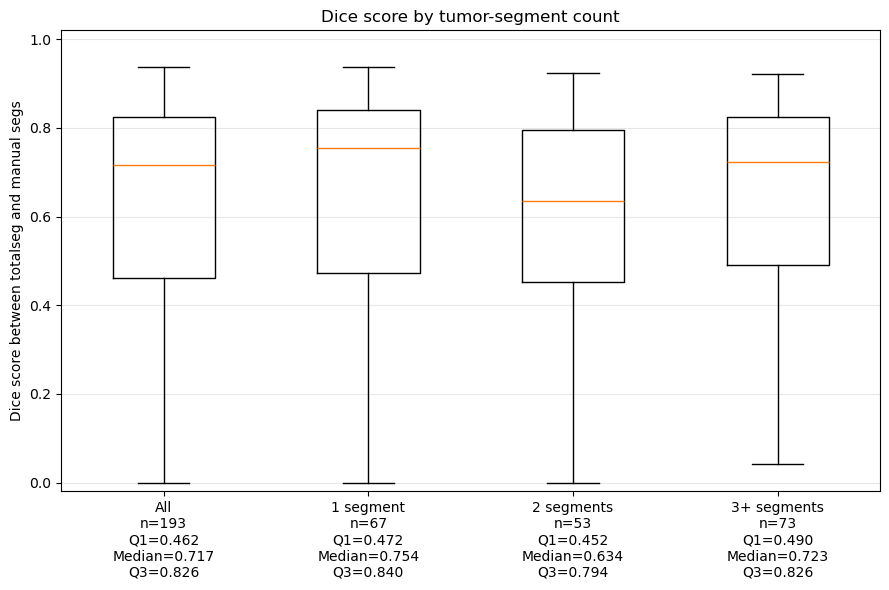

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(csv_file)
dice = pd.to_numeric(df["dice-score-totalseg-manual"], errors="coerce")
count = pd.to_numeric(df["tumor-segments"], errors="coerce")
groups = {"All": dice.dropna(), "1 segment": dice[count == 1].dropna(), "2 segments": dice[count == 2].dropna(), "3+ segments": dice[count >= 3].dropna()}

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(list(groups.values()), showfliers=True, whis=1.5, widths=0.5)
labels = []
for name, values in groups.items():
    q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
    labels.append(f"{name}\nn={len(values)}\nQ1={q1:.3f}\nMedian={median:.3f}\nQ3={q3:.3f}")
ax.set_xticks(range(1, 5))
ax.set_xticklabels(labels)
ax.set(ylabel="Dice score between totalseg and manual segs", ylim=(-0.02, 1.02), title="Dice score by tumor-segment count")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

In [46]:
good_experiments=[e for e in processed_experiments if e not in failed_experiments ]

In [48]:
with csv_file.open('w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['experiment', 'dice-score-totalseg-manual', 'dice-score-totalseg-nnunet', 'tumor-segments'])
    writer.writerows(zip(good_experiments, dice_scores_totalseg_manual, dice_scores_totalseg_nnunet, tumor_segments, strict=True))

In [52]:
np.average(dice_scores)

0.6561757236274249

In [51]:
np.average(dice_scores_totalseg_nnunet)

0.7632540650704721

In [5]:
scans[0]

{'Subject': 'CRLM-CT-1087',
 'Experiment': '12-10-1991-NA-CT_CHABDPEL_W_CONTRAST-52410',
 'StructScan': '2',
 'StructScanSerDesc': '',
 'SegScan1': '100',
 'SegScan1_SerDesc': 'Segmentation',
 'SegScan1_SOPClass': 'Seg'}